In [1]:
import numpy as np

In [2]:
import pandas as pd

In [6]:
df=pd.read_csv("sales_raw.csv")

In [8]:
df.head()

,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,10/1/2026,North,food,2.0,120
1,1002,10/1/2026,South,Books,1.0,250
2,1003,10/2/2026,North,Food,3.0,110
3,1004,10/2/2026,East,Stationery,4.0,50
4,1005,10/3/2026,SOUTH,books,2.0,250


In [9]:
df.tail(5)

,transaction_id,sale_date,region,category,quantity,unit_price
16,1017,10/9/2026,South,Food,3.0,95
17,1018,10/9/2026,NaN,Books,2.0,200
18,1019,10/10/2026,West,Stationery,2.0,40
19,1020,10/10/2026,North,Food,4.0,100
20,1003,10/2/2026,North,Food,3.0,110


In [11]:
print(df.columns.tolist())

['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price']


In [12]:
print(df.dtypes)

transaction_id      int64
sale_date          object
region             object
category           object
quantity          float64
unit_price         object
dtype: object


In [13]:
print(df.isna().sum())

transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64


In [14]:
df.duplicated().sum()

np.int64(1)

In [19]:
clean_df = df.copy()
before_cleaning = len(clean_df)

In [20]:
clean_df = clean_df.drop_duplicates()

In [22]:
clean_df["region"] = (
    clean_df["region"]
    .astype("string")
    .str.strip()
    .str.title())

In [24]:
clean_df["region"] = clean_df["region"].fillna("Unknown")

In [27]:
clean_df["category"] = clean_df["category"].fillna("Unknown")

In [28]:
clean_df["quantity"] = pd.to_numeric(
clean_df["quantity"], errors="coerce")

In [29]:
clean_df["unit_price"] = pd.to_numeric(
clean_df["unit_price"], errors="coerce")

In [30]:
clean_df["sale_date"] = pd.to_datetime(
    clean_df["sale_date"],
    errors="coerce")

In [31]:
clean_df = clean_df.dropna(
    subset=["transaction_id", "sale_date", "quantity", "unit_price"])

In [34]:
df.head()

,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,10/1/2026,North,food,2.0,120
1,1002,10/1/2026,South,Books,1.0,250
2,1003,10/2/2026,North,Food,3.0,110
3,1004,10/2/2026,East,Stationery,4.0,50
4,1005,10/3/2026,SOUTH,books,2.0,250


In [35]:
clean_df["revenue"] = (clean_df["quantity"] * clean_df["unit_price"])

In [39]:
region_summary = (
    clean_df.groupby("region")["revenue"].sum().sort_values(ascending=False).reset_index())

In [38]:
category_summary = (
    clean_df.groupby("category")["revenue"].sum().sort_values(ascending=False).reset_index())

In [40]:
import matplotlib.pyplot as plt

In [46]:
region_summary = clean_df.groupby("region")["revenue"].sum()

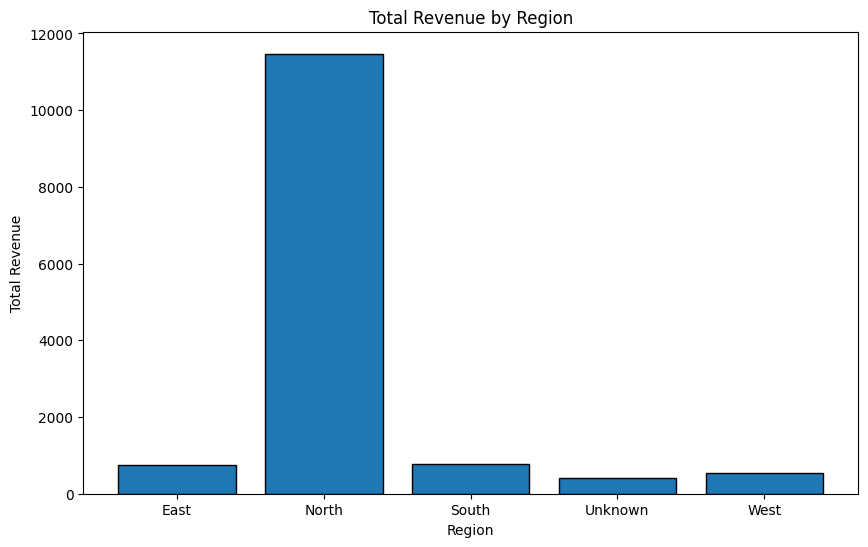

In [47]:
plt.figure(figsize=(10, 6))

plt.bar(
    region_summary.index,
    region_summary.values,
    edgecolor="black")
plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Revenue")
plt.show()

In [49]:
category_summary = clean_df.groupby("category")["revenue"].sum()

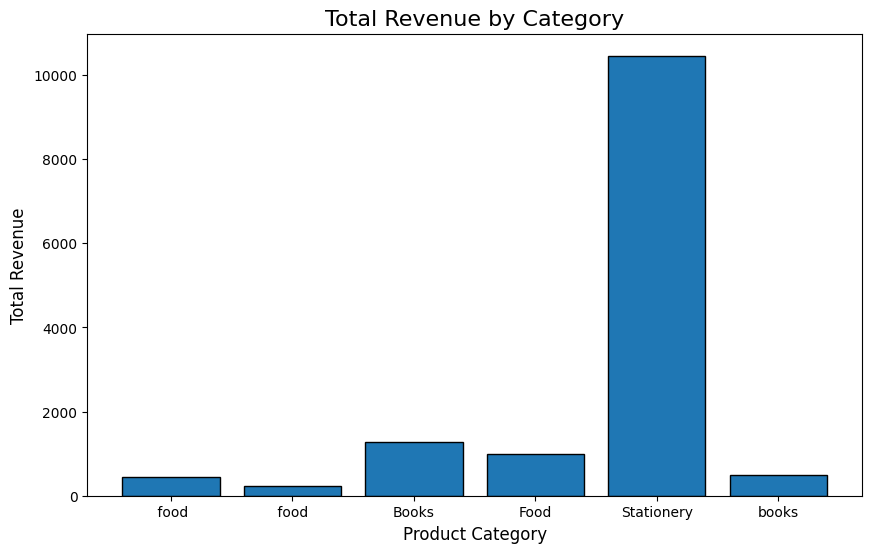

In [50]:
plt.figure(figsize=(10, 6))

plt.bar(
    category_summary.index,
    category_summary.values,
    edgecolor="black")
plt.title("Total Revenue by Category", fontsize=16)
plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Total Revenue", fontsize=12)
plt.show()